
### WEEK 4: EXPLORATORY DATA ANALYSIS

#### Project Title
Spotify Music Trends and Audio Features Analysis Using Data Science and Visualization

#### Course
24ADI204 – Data Science and Visualization

#### Team
DSV Team 9

#### Aim
To explore Spotify music trends and analyze the relationships between song popularity and audio features using statistical methods and data visualization.

#### Objectives
1. Understand the distribution of Spotify song popularity.
2. Analyze audio features such as danceability, energy, tempo, and valence.
3. Visualize the duration and musical characteristics of songs.
4. Compare explicit and non-explicit tracks.
5. Examine different album types.
6. Study relationships between audio features and popularity.
7. Identify correlations between numerical attributes.

#### Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook



### 1. Importing Libraries and Loading the Dataset

The required Python libraries are imported to perform exploratory data analysis.

- **Pandas:** Used for data manipulation and analysis.
- **NumPy:** Used for numerical operations.
- **Matplotlib:** Used to create statistical graphs.
- **Seaborn:** Used to generate advanced data visualizations.
- **Pathlib:** Used to locate the dataset file.

The original Spotify dataset is loaded from `DSV_Team-9_Raw_Dataset.csv`.

The dataset contains 19,335 rows and 46 columns.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

file_path = Path("DSV_Team-9_Raw_Dataset.csv")
if not file_path.is_file():
    print("Dataset not found in:", Path.cwd())
    file_path = Path(input("Enter the full path of your CSV file: ").strip().strip('"'))
if not file_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {file_path}")

try:
    df = pd.read_csv(file_path, low_memory=False)
except UnicodeDecodeError:
    df = pd.read_csv(file_path, encoding="latin1", low_memory=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
if df.shape[1] != 46:
    print("Warning: expected the original 46-column dataset; verify the selected file.")


Dataset loaded successfully!
Dataset shape: (19335, 46)



### 2. Inspecting Dataset Structure

The dataset structure is examined to understand the available attributes.

The `df.columns` function displays the column names, while `df.dtypes` identifies their data types.

This helps distinguish numerical and categorical attributes and identify columns requiring conversion before visualization.


In [2]:

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)


Column names:
['id', 'artists', 'available_markets', 'disc_number', 'duration_ms.x', 'explicit', 'href', 'is_local', 'name', 'popularity', 'preview_url', 'track_number', 'type.x', 'uri.x', 'album.album_type', 'album.artists', 'album.available_markets', 'album.href', 'album.id', 'album.images', 'album.name', 'album.release_date', 'album.release_date_precision', 'album.total_tracks', 'album.type', 'album.uri', 'album.external_urls.spotify', 'external_ids.isrc', 'external_urls.spotify', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'type.y', 'uri.y', 'track_href', 'analysis_url', 'duration_ms.y', 'time_signature']

Data types:
id                                  str
artists                             str
available_markets                   str
disc_number                       int64
duration_ms.x                       str
explicit                            str
href                                st


### 3. Checking Missing Values and Duplicate Records

Missing values and duplicate records can affect the reliability of data analysis.

The `isnull()` function is used to identify missing values, while `duplicated()` checks for repeated rows.

This analysis helps understand the quality of the dataset before performing statistical analysis and visualization.


In [3]:

print("Duplicate rows:", df.duplicated().sum())

missing = df.isnull().sum()
display(missing[missing > 0].sort_values(ascending=False))


Duplicate rows: 0


preview_url                     7524
type.y                             7
uri.y                              7
danceability                       7
external_urls.spotify              7
external_ids.isrc                  7
album.external_urls.spotify        7
track_href                         7
analysis_url                       7
duration_ms.y                      7
time_signature                     7
mode                               7
loudness                           7
tempo                              7
valence                            7
liveness                           7
instrumentalness                   7
acousticness                       7
speechiness                        7
key                                7
energy                             7
album.uri                          4
album.type                         4
album.release_date_precision       4
album.release_date                 4
album.total_tracks                 4
album.href                         2
i


### 4. Converting Numerical Attributes

Some numerical attributes may be stored as text in the original dataset.

The `pd.to_numeric()` function is used to convert selected attributes into numerical form.

Invalid values are converted into missing values using `errors="coerce"`.

The song duration is also converted from milliseconds into minutes using the formula:

Duration (minutes) = Duration (milliseconds) / 60000

This makes the dataset suitable for statistical calculations and visualizations.


In [4]:

features = [
    "popularity", "danceability", "energy", "loudness",
    "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo", "duration_ms.y"
]

for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["duration_minutes"] = df["duration_ms.y"] / 60000

print("Numeric conversion completed.")


Numeric conversion completed.



### 5. Descriptive Statistical Analysis

Descriptive statistics summarize the numerical characteristics of the Spotify dataset.

The `describe()` function calculates the count, mean, standard deviation, minimum, maximum, and quartile values.

This analysis helps understand the central tendency, variation, and range of Spotify audio features.


In [5]:

display(df[features].describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
popularity,19333.0,58.14,19.91,0.00,55.00,64.00,70.00,100.00
danceability,19328.0,0.62,0.18,0.00,0.51,0.64,0.75,0.98
energy,19328.0,0.58,0.24,0.00,0.44,0.62,0.76,1.00
loudness,19328.0,-8.61,5.80,-54.38,-9.71,-6.82,-5.08,1.06
speechiness,19328.0,0.11,0.11,0.00,0.04,0.06,0.13,0.95
acousticness,19328.0,0.31,0.32,0.00,0.04,0.18,0.52,1.00
instrumentalness,19328.0,0.10,0.27,0.00,0.00,0.00,0.00,1.00
liveness,19328.0,0.18,0.15,0.00,0.10,0.12,0.22,0.99
valence,19328.0,0.49,0.24,0.00,0.30,0.49,0.68,1.00
tempo,19328.0,119.79,30.97,0.00,94.99,119.89,140.07,230.40



### 6. Distribution of Track Popularity

A histogram is used to visualize the distribution of Spotify song popularity scores.

The popularity score indicates the relative popularity of a track.

The histogram shows how frequently different popularity scores occur in the dataset.

A Kernel Density Estimate (KDE) curve is included to provide a smoother representation of the distribution.


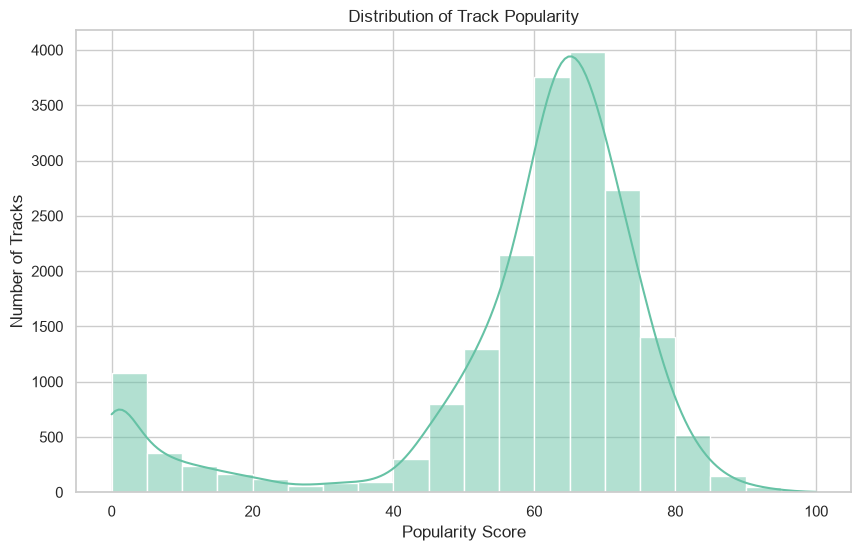

In [6]:

sns.histplot(df["popularity"].dropna(), bins=20, kde=True)
plt.title("Distribution of Track Popularity")
plt.xlabel("Popularity Score")
plt.ylabel("Number of Tracks")
plt.show()



### 7. Distribution of Spotify Audio Features

Histograms are generated for six important Spotify audio features:

- **Danceability:** Indicates how suitable a song is for dancing.
- **Energy:** Represents the intensity and activity of a song.
- **Valence:** Indicates the musical positivity of a song.
- **Acousticness:** Estimates whether a song is acoustic.
- **Speechiness:** Measures the presence of spoken words.
- **Instrumentalness:** Estimates the likelihood that a track contains no vocals.

These distributions help identify common characteristics and variations among Spotify songs.


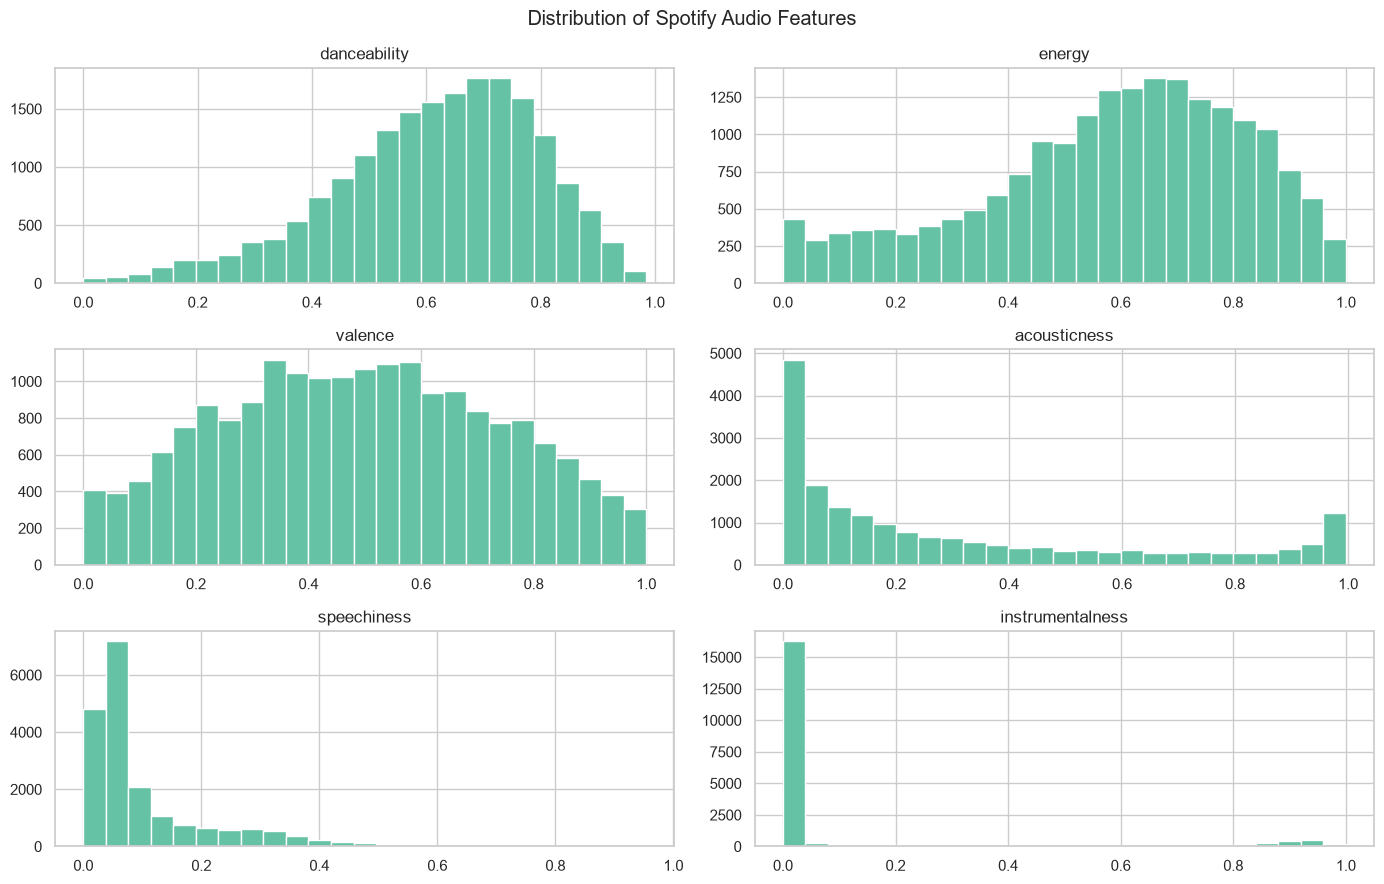

In [7]:

cols = ["danceability", "energy", "valence", "acousticness",
        "speechiness", "instrumentalness"]

df[cols].hist(figsize=(14, 9), bins=25, edgecolor="white")
plt.suptitle("Distribution of Spotify Audio Features")
plt.tight_layout()
plt.show()



### 8. Distribution of Track Tempo

Tempo represents the speed of a song and is measured in beats per minute (BPM).

A histogram with a KDE curve is used to visualize the distribution of tempo values.

This analysis helps identify common tempo ranges and understand variations in the speed of Spotify songs.


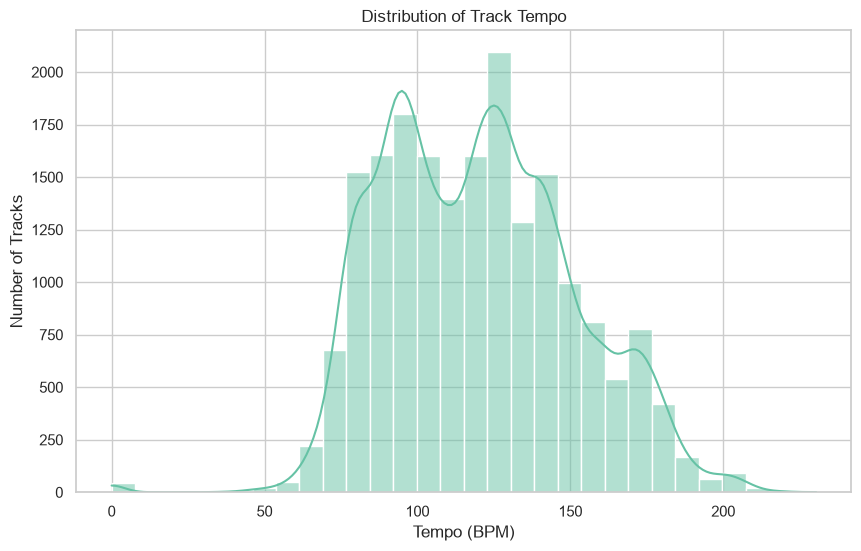

In [8]:

sns.histplot(df["tempo"].dropna(), bins=30, kde=True)
plt.title("Distribution of Track Tempo")
plt.xlabel("Tempo (BPM)")
plt.ylabel("Number of Tracks")
plt.show()



### 9. Distribution of Song Duration

Song duration represents the total playing time of a track.

The duration values are converted from milliseconds into minutes for easier interpretation.

A histogram is used to examine the distribution of song lengths.

This analysis helps identify common song durations and unusually short or long tracks.


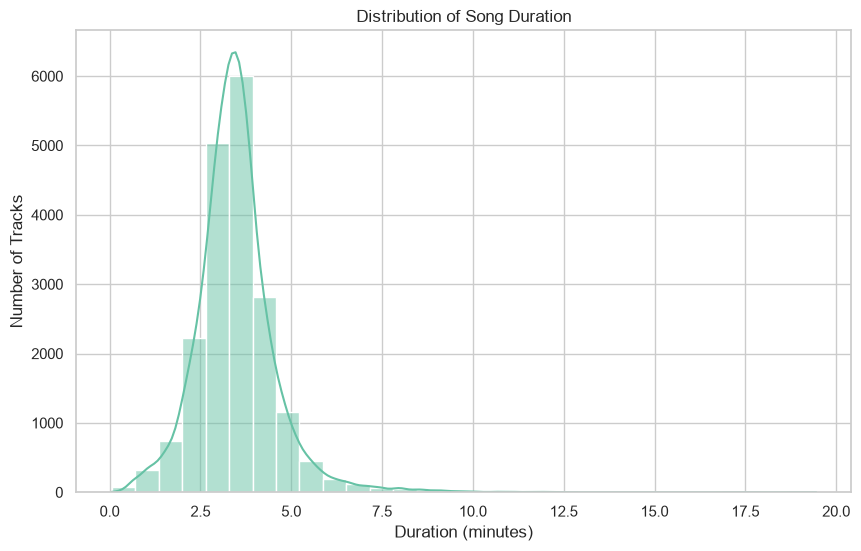

In [9]:

sns.histplot(df["duration_minutes"].dropna(), bins=30, kde=True)
plt.title("Distribution of Song Duration")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Tracks")
plt.show()



### 10. Boxplot Analysis of Audio Features

Boxplots are used to examine the spread and variation of numerical audio features.

They display the median, quartiles, and potential outliers.

Separate boxplots are generated for danceability, energy, valence, acousticness, speechiness, and instrumentalness.

This visualization helps identify differences in feature distributions and possible extreme values.


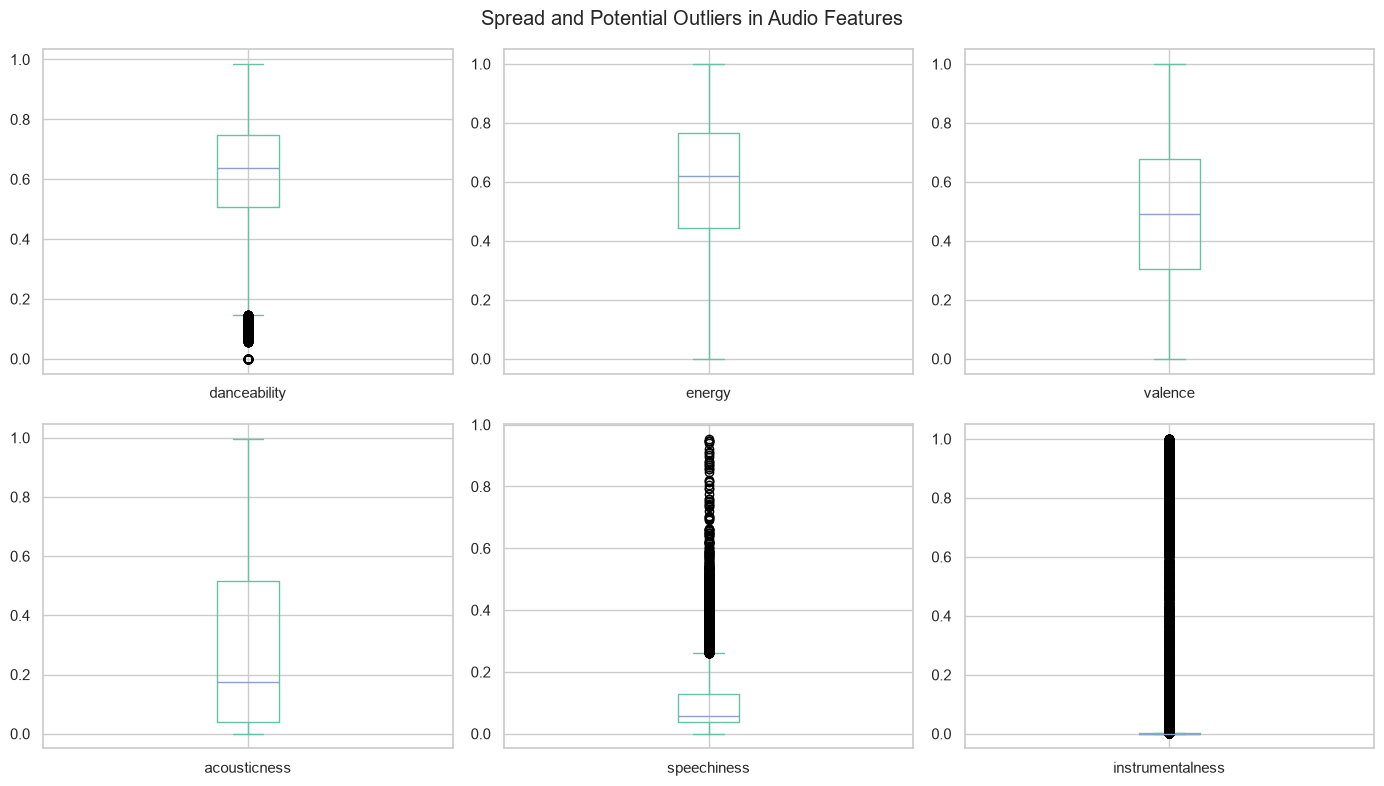

In [10]:

df[cols].plot(
    kind="box",
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    sharex=False
)

plt.suptitle("Spread and Potential Outliers in Audio Features")
plt.tight_layout()
plt.show()



### 11. Explicit versus Non-Explicit Track Counts

Spotify tracks are classified as explicit or non-explicit based on their content labels.

- **Explicit:** Tracks marked as containing mature or explicit content.
- **Non-explicit:** Tracks not marked as containing explicit content.

The explicit status is converted into readable categories.

A count plot is used to compare the number of tracks belonging to each category.

This analysis helps understand the distribution of explicit and non-explicit songs in the dataset.


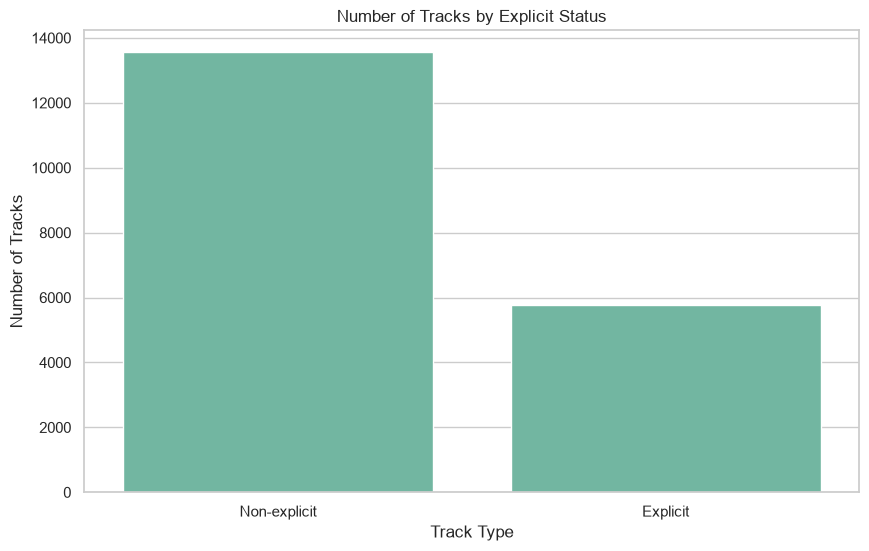

In [11]:

df["explicit"] = (
    df["explicit"].astype("string").str.strip().str.upper()
    .map({"TRUE": "Explicit", "FALSE": "Non-explicit"})
)

sns.countplot(data=df, x="explicit", order=["Non-explicit", "Explicit"])
plt.title("Number of Tracks by Explicit Status")
plt.xlabel("Track Type")
plt.ylabel("Number of Tracks")
plt.show()



### 12. Distribution of Tracks by Album Type

Spotify tracks are associated with different types of releases, such as albums, singles, and compilations.

A count plot is used to visualize the number of tracks belonging to each album type.

This analysis helps identify the most frequently represented release categories in the dataset.


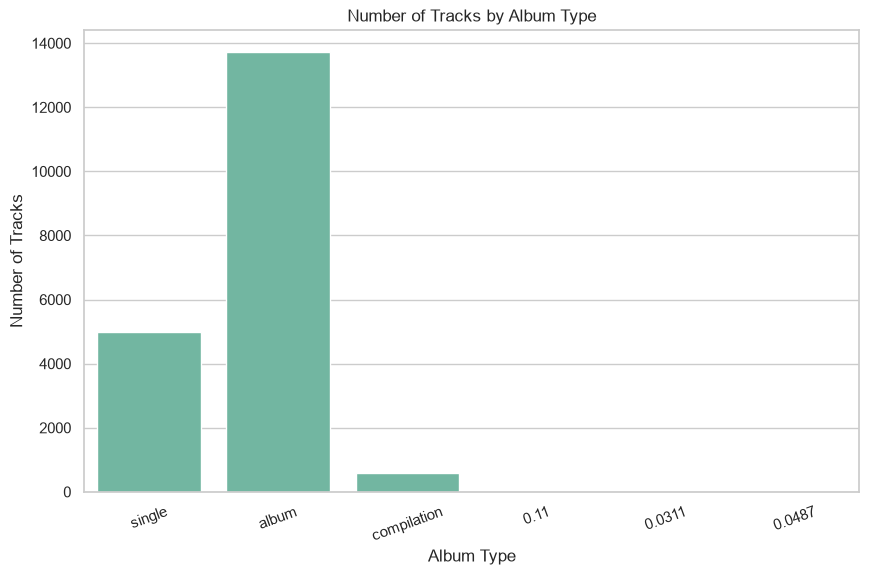

In [12]:

sns.countplot(data=df, x="album.album_type")
plt.title("Number of Tracks by Album Type")
plt.xlabel("Album Type")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=20)
plt.show()



### 13. Relationship Between Danceability and Popularity

Danceability indicates how suitable a song is for dancing based on musical characteristics.

A scatter plot is used to examine the relationship between danceability and Spotify popularity scores.

Each point represents a song in the dataset.

This visualization helps determine whether highly danceable songs tend to have higher popularity scores.


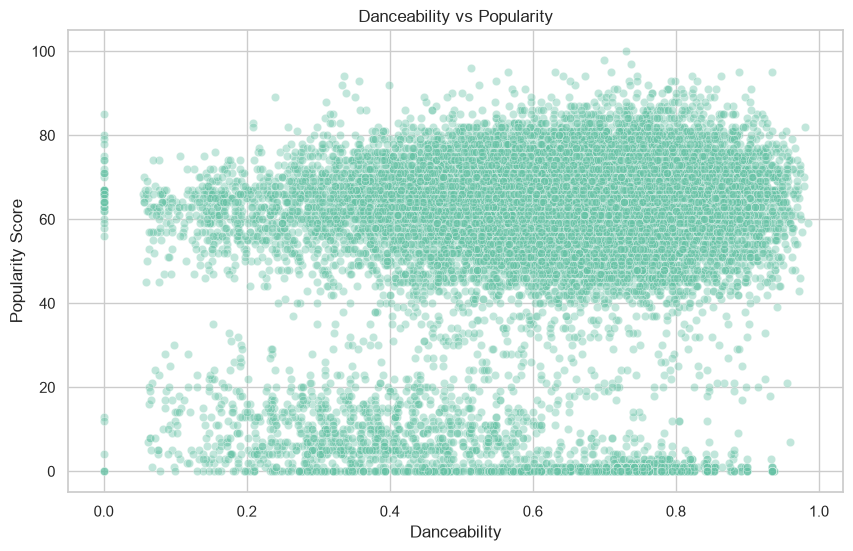

In [13]:

sns.scatterplot(data=df, x="danceability", y="popularity", alpha=0.4)
plt.title("Danceability vs Popularity")
plt.xlabel("Danceability")
plt.ylabel("Popularity Score")
plt.show()



### 14. Relationship Between Energy and Popularity

Energy represents the intensity and activity level of a song.

A scatter plot is used to examine the relationship between energy and Spotify popularity scores.

The visualization helps identify whether energetic songs tend to receive higher popularity scores.

The distribution of points is used to observe possible positive, negative, or weak relationships.


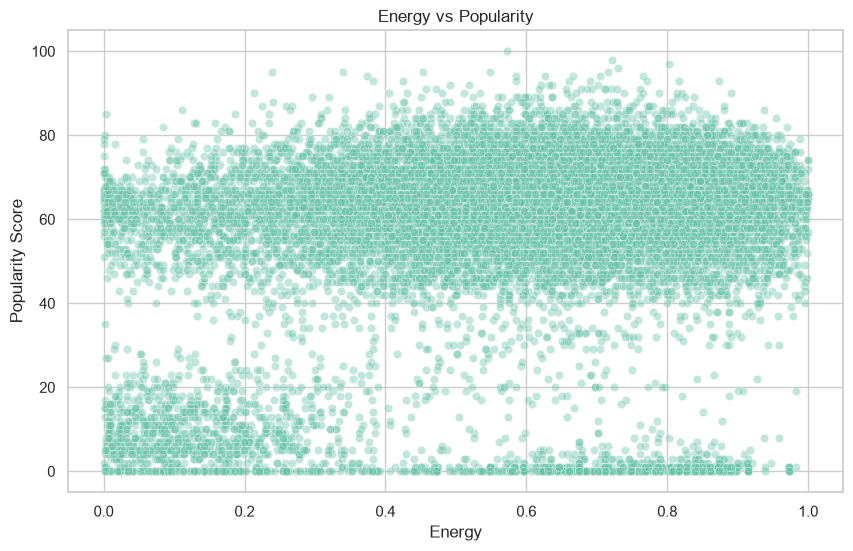

In [14]:

sns.scatterplot(data=df, x="energy", y="popularity", alpha=0.4)
plt.title("Energy vs Popularity")
plt.xlabel("Energy")
plt.ylabel("Popularity Score")
plt.show()



### 15. Relationship Between Acousticness and Popularity

Acousticness measures the likelihood that a song is acoustic.

A scatter plot is used to analyze the relationship between acousticness and Spotify popularity.

This visualization helps determine whether acoustic characteristics are associated with differences in song popularity.


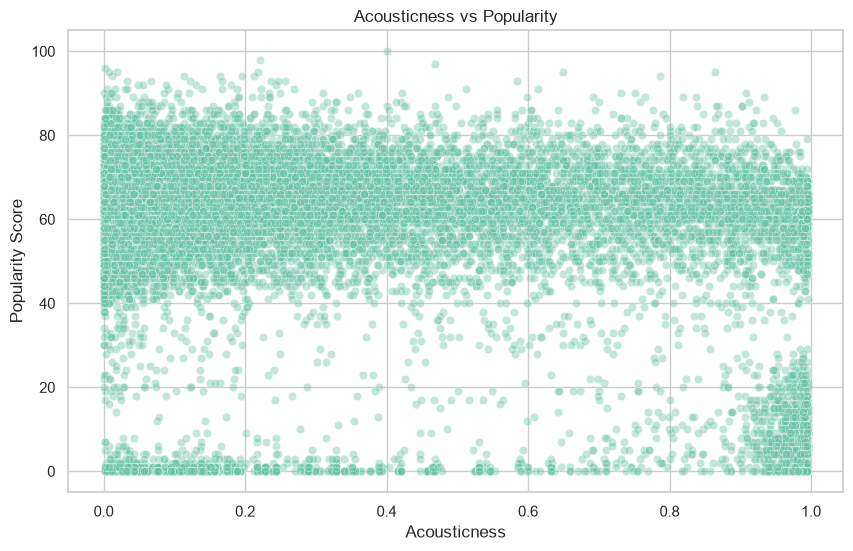

In [15]:

sns.scatterplot(data=df, x="acousticness", y="popularity", alpha=0.4)
plt.title("Acousticness vs Popularity")
plt.xlabel("Acousticness")
plt.ylabel("Popularity Score")
plt.show()



### 16. Comparison of Popularity by Explicit Status

A boxplot is used to compare the popularity scores of explicit and non-explicit Spotify tracks.

The visualization displays the median, quartiles, and potential outliers for both categories.

This analysis helps identify differences in popularity distributions between explicit and non-explicit songs.


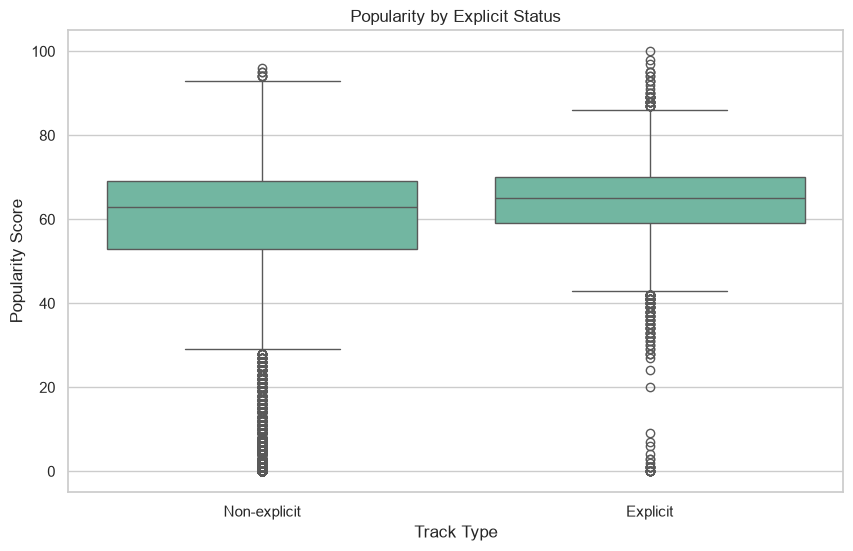

In [16]:

sns.boxplot(data=df, x="explicit", y="popularity")
plt.title("Popularity by Explicit Status")
plt.xlabel("Track Type")
plt.ylabel("Popularity Score")
plt.show()



### 17. Correlation Analysis of Spotify Audio Features

Correlation analysis measures the strength and direction of linear relationships between numerical attributes.

A correlation heatmap is generated using the `corr()` function.

Correlation coefficients range from -1 to +1.

- **+1:** Perfect positive correlation.
- **0:** No linear correlation.
- **-1:** Perfect negative correlation.

The heatmap helps identify relationships among popularity, danceability, energy, loudness, tempo, valence, and other audio features.

This analysis is useful for understanding feature relationships and supporting future feature selection.


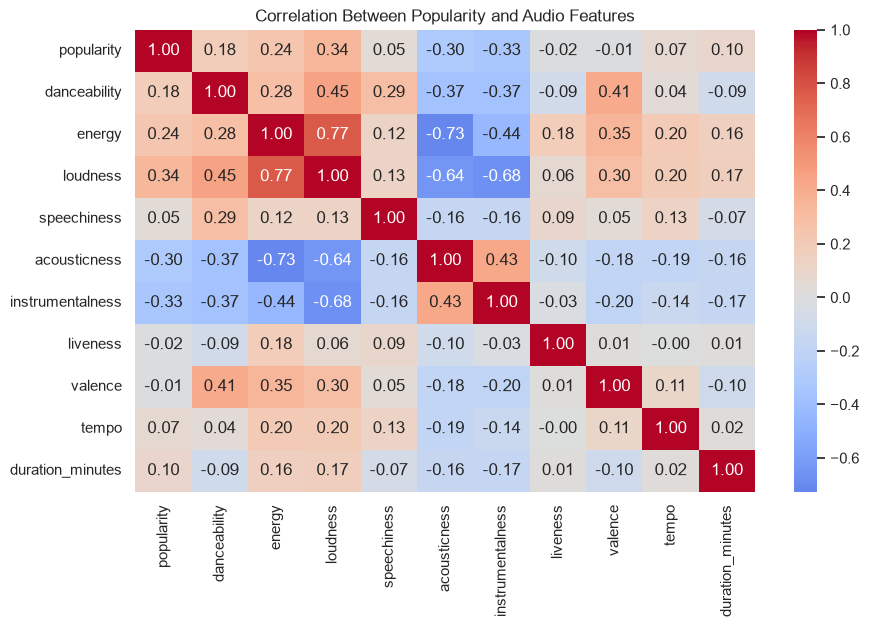

In [17]:

corr_cols = [
    "popularity", "danceability", "energy", "loudness",
    "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo", "duration_minutes"
]

corr = df[corr_cols].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Popularity and Audio Features")
plt.show()



### 18. Identifying Features Associated with Popularity

The correlation coefficients between popularity and other numerical attributes are extracted from the correlation matrix.

The five features with the highest positive correlation coefficients and the five features with the lowest coefficients are displayed.

This analysis helps identify which musical characteristics have stronger positive or negative linear associations with popularity.

Correlation indicates association and does not necessarily imply causation.


In [18]:

print("Features most positively correlated with popularity:")
display(corr["popularity"].drop("popularity").sort_values(ascending=False).head(5))

print("Features most negatively correlated with popularity:")
display(corr["popularity"].drop("popularity").sort_values().head(5))


Features most positively correlated with popularity:


loudness            0.337191
energy              0.241089
danceability        0.178095
duration_minutes    0.102250
tempo               0.067058
Name: popularity, dtype: float64

Features most negatively correlated with popularity:


instrumentalness   -0.330214
acousticness       -0.295448
liveness           -0.016314
valence            -0.011696
speechiness         0.045868
Name: popularity, dtype: float64


### 19. Conclusion

Exploratory Data Analysis was performed on the Spotify Songs dataset using Python, Pandas, Matplotlib, and Seaborn.

The analysis examined song popularity, audio feature distributions, tempo, song duration, album types, and explicit content classification.

Histograms were used to study numerical distributions, boxplots were used to identify potential outliers, and scatter plots were used to examine relationships between audio features and popularity.

A correlation heatmap was generated to examine linear relationships between numerical attributes.

The analysis provides a foundation for understanding Spotify music trends and identifying features that may be useful in further data science analysis.

#### Result

Exploratory Data Analysis of the Spotify Songs dataset was carried out using statistical summaries and visualizations.
